#### Load Packages

In [2]:
#Basic
import os
import pandas as pd
import numpy as np

#Chem
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors, PandasTools, rdFingerprintGenerator
from rdkit.DataStructs import TanimotoSimilarity

#Visualization
import matplotlib.pyplot as plt
import seaborn as sns
# Set up a consistent plotting style
plt.style.use("default")
sns.set_palette("husl")

# Modeling Training and Evaluation
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.metrics import (make_scorer, matthews_corrcoef, classification_report, roc_curve, auc, 
                             accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, 
                             multilabel_confusion_matrix, ConfusionMatrixDisplay)
from sklearn.dummy import DummyClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.base import clone

# Jupyter command to make more than one output show up
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [3]:
# Set Random Seed for Reproducibility
RANDOM_SEED = 1147
np.random.seed(RANDOM_SEED)

#### Load Dataset

In [5]:
#url = "https://zenodo.org/records/11062077/files/dataset_final.csv?download=1"
#df = pd.read_csv("~/data/raw/apistox_full_raw.csv")

DATA_DIR = "data/raw"
DATA_FILE = os.path.join(DATA_DIR, "apistox_full_raw.csv")
df = pd.read_csv(DATA_FILE)
display(df.head())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

,name,CID,CAS,SMILES,source,year,toxicity_type,herbicide,fungicide,insecticide,other_agrochemical,label,ppdb_level
0,Ethanedioic acid,971,144-62-7,O=C(O)C(=O)O,ECOTOX,1832,Contact,0,0,0,0,0,0
1,Para-cymene,7463,99-87-6,Cc1ccc(C(C)C)cc1,BPDB,1833,Other,0,0,0,1,0,1
2,Kieselguhr,24261,61790-53-2,O=[Si]=O,ECOTOX,1833,Contact,0,0,0,0,0,0
3,Benzoic acid,243,65-85-0,O=C(O)c1ccccc1,ECOTOX,1833,Contact,1,1,1,0,0,1
4,Tetradifon (Ref: ENT 23737),8305,116-29-0,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,PPDB,1836,Oral,0,0,0,1,1,1


Shape: (1035, 13)
Columns: ['name', 'CID', 'CAS', 'SMILES', 'source', 'year', 'toxicity_type', 'herbicide', 'fungicide', 'insecticide', 'other_agrochemical', 'label', 'ppdb_level']


In [6]:
# create DATA_FILE for other 6 datasets
DATA_FILE1 = os.path.join(DATA_DIR, "random_train_raw.csv")
DATA_FILE2 = os.path.join(DATA_DIR, "random_test_raw.csv")
DATA_FILE3 = os.path.join(DATA_DIR, "maxmin_train_raw.csv")
DATA_FILE4 = os.path.join(DATA_DIR, "maxmin_test_raw.csv")
DATA_FILE5 = os.path.join(DATA_DIR, "time_train_raw.csv")
DATA_FILE6 = os.path.join(DATA_DIR, "time_test_raw.csv")


### EDA
(1) Creating Features

(2) Correlation Analysis

(3) Tanimoto Similarity

In [7]:
### Create Fingerprints ###
#add 'mol' molecule type as a new column to the dataframe
PandasTools.AddMoleculeColumnToFrame(df, smilesCol='SMILES', molCol='molecule')

#create a morgan fingerprints data frame
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

# Generate fingerprints for all molecules
fingerprints = []
for mol in df['molecule']:
    fp = morgan_gen.GetFingerprint(mol)
    fingerprints.append(fp.ToList())

# Convert to DataFrame with indexed column names
fp_columns = [f'Morgan_bit_{i}' for i in range(2048)]
fingerprint_df = pd.DataFrame(fingerprints, columns=fp_columns, index=df.index)
df_fp = pd.concat([df, fingerprint_df], axis=1)

print(f"Dataframe of fingerprints shape: {fingerprint_df.shape}")

#find the number of bits on for each MorganFP


#calculte the mean and sd of the tanimoto similarities for the three classes

#create two filtered dataframes for nontoxic and toxic

nontox_df = df[df['ppdb_level'] == 0]
toxic_df = df[df['ppdb_level'] == 2]

print(len(nontox_df), len(toxic_df))
df_fp.shape

Dataframe of fingerprints shape: (1035, 2048)
177 171


(1035, 2062)

In [8]:
### Computing Tanimoto Similarity ###
def compare_fp_parameters(mols, molecule_names, radius, fp_size, column):
    generator = rdFingerprintGenerator.GetMorganGenerator(
        radius=radius,
        fpSize=fp_size
    )
    fingerprints = [generator.GetFingerprint(mol) for mol in column]

    matrix = []
    for fp_a in fingerprints:
        row = [
            TanimotoSimilarity(fp_a, fp_b)
            for fp_b in fingerprints
        ]
        matrix.append(row)

    return pd.DataFrame(matrix)
mols_nontox = nontox_df['molecule'].tolist() #.iloc[:177].tolist()
names_nontox = nontox_df['name'].tolist() #[:177].astype(str).tolist()

print(len(mols_nontox), len(names_nontox))

177 177


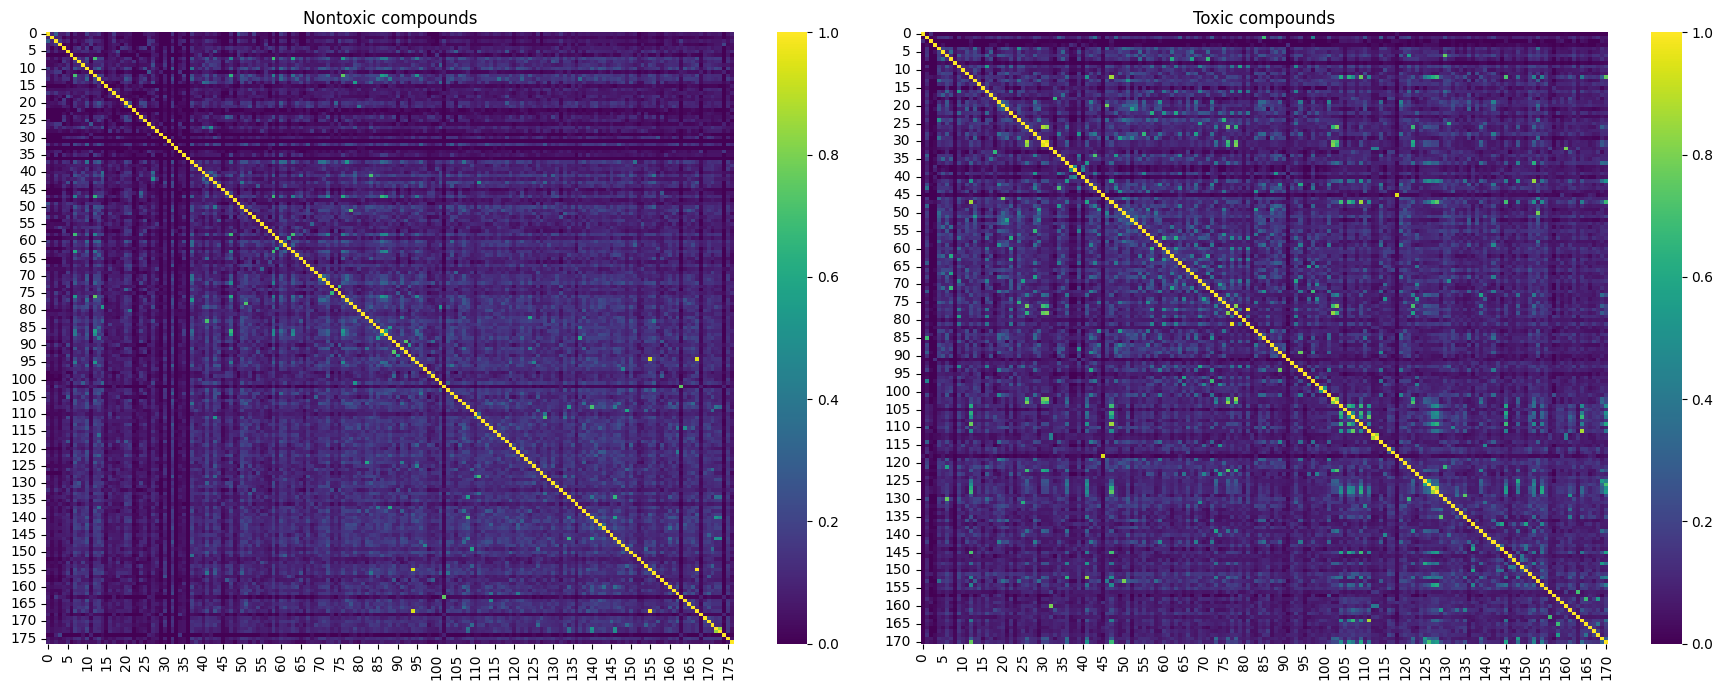

In [9]:
### Plot Similarities in Nontoxic and Toxic ###
similarity_nontox = compare_fp_parameters(
    mols_nontox, names_nontox, radius=2, fp_size=1024, column = nontox_df['molecule']) 
similarity_tox = compare_fp_parameters(
    mols_nontox, names_nontox, radius=2, fp_size=1024, column = toxic_df['molecule'])
fig, axes = plt.subplots(1, 2, figsize=(18, 7)) # plot matrices side-by-side

sns.heatmap(similarity_nontox, ax=axes[0], cmap="viridis", vmin=0, vmax=1)
axes[0].set_title("Nontoxic compounds")

sns.heatmap(similarity_tox, ax=axes[1], cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Toxic compounds")

plt.tight_layout()
plt.show();

### Train/Test Split
The ApisTox dataset comes with three prepared train-test splits to encourage benchmarking and collaboration with the dataset. The Train/Test is split 80-20. The splits were prepared with different validation goals in mind: two are interpolative and one is extrapolative. Interpolative splits validate predictive performance inside the domain of the dataset. Extrapolative splits aim to verify out-of-domain generalization of models to structurally novel compounds. All of the details below are summarized from the 2025 ApisTox publication:
- **Stratified Random Split**

    Interpolative. Data is stratified by binary toxic and nontoxic class labels. This split may be prone to some data leakage which artificially increases test score, as this split is susceptible to clustering in chemical space (some very similar compounds make their way into both train and test sets). Scikit-learn used to prepare split.

- **Maximum Diversity Split (Max-Min Split)**

    Interpolative. The 'Maximum Diversity Picking Algorithm' is used to select test molecules so that the sum of the distances in the test set is maximized. Dice similarities with 1024 bit ECFP4 fingerprints, and the 'DeepChem' package were used to prepare this split.

- **Time Split (Chronological Split by Pubchem Date)**

    Extrapolative. The newest molecules (determined by date first appearing in bee literature, source: PubChem) are put into the test set. The assumption is that new substances are introduced over time. This is seen as an alternative to the 'scaffold split' in which new chemical 'scaffolds' (chemical moieites) are introduced over time. Pandas used to prepare split.


In [10]:
### Import All Pre-Made ApisTox Train-Test Splits ###

# load data locally


#df = pd.read_csv(DATA_FILE)
#print(f"✅ Loaded data from {DATA_FILE}, shape = {df.shape}")

random_train = pd.read_csv(DATA_FILE1)
random_test = pd.read_csv(DATA_FILE2)
time_train = pd.read_csv(DATA_FILE3)
time_test = pd.read_csv(DATA_FILE4)
maxmin_train = pd.read_csv(DATA_FILE5)
maxmin_test = pd.read_csv(DATA_FILE6)

if FileNotFoundError:
    # Fallback: try to load from GitHub raw URL
    url1 = "https://github.com/ella-satt/che1147-bees/blob/main/data/raw/random_train_raw.csv"
    url2 = "https://github.com/ella-satt/che1147-bees/blob/main/data/raw/random_test_raw.csv"
    url3 = "https://github.com/ella-satt/che1147-bees/blob/main/data/raw/maxmin_train_raw.csv"
    url4 = "https://github.com/ella-satt/che1147-bees/blob/main/data/raw/maxmin_test_raw.csv"
    url5 = "https://github.com/ella-satt/che1147-bees/blob/main/data/raw/time_train_raw.csv"
    url6 = "https://github.com/ella-satt/che1147-bees/blob/main/data/raw/time_test_raw.csv"

print(f"Train Set Size Verification -- Random: {random_train.shape}, Time: {time_train.shape}, MaxMin: {maxmin_train.shape} ")
print(f"Test Set Size Verification -- Random: {random_test.shape}, Time: {time_test.shape}, MaxMin: {maxmin_test.shape} ")

Train Set Size Verification -- Random: (828, 13), Time: (828, 13), MaxMin: (828, 13) 
Test Set Size Verification -- Random: (207, 13), Time: (207, 13), MaxMin: (207, 13) 


Now, with the pre-made splits, add fingerprints to each dataframe. Also, define features and target. Finally, define a dictionary where model error metrics will be stored.

In [11]:
#set morgan fp generating params
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

In [12]:
# Define a function to add fingerprints to each of these datasets.
def add_fp(dataframe):
    if dataframe.shape[1] < 1000: #use to not accidentally add columns twice

        PandasTools.AddMoleculeColumnToFrame(dataframe, smilesCol='SMILES', molCol='molecule')

        morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    
        # Generate fingerprints for all molecules
        fingerprints = []
        for mol in dataframe['molecule']:
            fp = morgan_gen.GetFingerprint(mol)
            fingerprints.append(fp.ToList())

        # Convert to DataFrame with indexed column names
        fp_columns = [f'Morgan_bit_{i}' for i in range(2048)]
        fingerprint_df = pd.DataFrame(fingerprints, columns=fp_columns, index=dataframe.index)
        
        dataframe = pd.concat([dataframe, fingerprint_df], axis=1)
        
        return dataframe
    else:
        return dataframe

In [13]:
#apply fingerprint function to each ApisTox split 
#splits = [random_train, random_test, time_train, time_test, maxmin_train, maxmin_test]
random_train = add_fp(random_train)
random_test = add_fp(random_test)
time_train = add_fp(time_train)
time_test = add_fp(time_test)
maxmin_train = add_fp(maxmin_train)
maxmin_test = add_fp(maxmin_test)

In [14]:
#define features (per split) and target and drop features with zero variance

#define initial features
TARGET = "ppdb_level"
RANDOM_FEATURES = [col for col in random_train.columns if col.startswith("Morgan_bit_")]
MAXMIN_FEATURES = [col for col in maxmin_train.columns if col.startswith("Morgan_bit_")]
TIME_FEATURES = [col for col in time_train.columns if col.startswith("Morgan_bit_")]

# Find and print the number of all zero-variance features by split
random_redundant_features = [RANDOM_FEATURES for RANDOM_FEATURES in random_train.columns if random_train[RANDOM_FEATURES].nunique() == 1]
maxmin_redundant_features = [MAXMIN_FEATURES for MAXMIN_FEATURES in maxmin_train.columns if maxmin_train[MAXMIN_FEATURES].nunique() == 1]
time_redundant_features = [TIME_FEATURES for TIME_FEATURES in time_train.columns if time_train[TIME_FEATURES].nunique() == 1]
print(f'Number of Zero Variance Features by Split -- Random: {len(random_redundant_features)}, MaxMin: {len(maxmin_redundant_features)}, Time: {len(time_redundant_features)}')

# Dropping Features with Zero Variance -- w/ print statements to confirm
print(f'\n\n Random Split Shape Before Drop -- Train: {random_train.shape} -- Test: {random_test.shape}')
random_train = random_train.drop(columns=random_redundant_features)
random_test = random_test.drop(columns=random_redundant_features)
print(f'Random Split Shape After Drop -- Train: {random_train.shape} -- Test: {random_test.shape}')

print(f'MaxMin Split Shape Before Drop -- Train: {maxmin_train.shape} -- Test: {maxmin_test.shape}')
maxmin_train = maxmin_train.drop(columns=maxmin_redundant_features)
maxmin_test = maxmin_test.drop(columns=maxmin_redundant_features)
print(f'MaxMin Split Shape After Drop -- Train: {maxmin_train.shape} -- Test: {maxmin_test.shape}')

print(f'Time Split Shape Before Drop -- Train: {time_train.shape} -- Test: {time_test.shape}')
time_train = time_train.drop(columns=time_redundant_features)
time_test = time_test.drop(columns=time_redundant_features)
print(f'Time Split Shape After Drop -- Train: {time_train.shape} -- Test: {time_test.shape}')

#update features by column -- w/ print statements to confirm
print(f'\n\n Number of Features by Split -- Random: {len(RANDOM_FEATURES)}, MaxMin: {len(MAXMIN_FEATURES)}, Time: {len(TIME_FEATURES)}')
RANDOM_FEATURES = [col for col in random_train.columns if col.startswith("Morgan_bit_")]
MAXMIN_FEATURES = [col for col in maxmin_train.columns if col.startswith("Morgan_bit_")]
TIME_FEATURES = [col for col in time_train.columns if col.startswith("Morgan_bit_")]
print(f'Updated Number of Features by Split -- Random: {len(RANDOM_FEATURES)}, MaxMin: {len(MAXMIN_FEATURES)}, Time: {len(TIME_FEATURES)}')


Number of Zero Variance Features by Split -- Random: 100, MaxMin: 141, Time: 134


 Random Split Shape Before Drop -- Train: (828, 2062) -- Test: (207, 2062)
Random Split Shape After Drop -- Train: (828, 1962) -- Test: (207, 1962)
MaxMin Split Shape Before Drop -- Train: (828, 2062) -- Test: (207, 2062)
MaxMin Split Shape After Drop -- Train: (828, 1921) -- Test: (207, 1921)
Time Split Shape Before Drop -- Train: (828, 2062) -- Test: (207, 2062)
Time Split Shape After Drop -- Train: (828, 1928) -- Test: (207, 1928)


 Number of Features by Split -- Random: 2048, MaxMin: 2048, Time: 2048
Updated Number of Features by Split -- Random: 1948, MaxMin: 1907, Time: 1914


### VERY Important Note About Calling Features:
Each of the splits has its own set of features. When training models, it is necessary to use random_train(RANDOM_FEATURES), maxmin_train(MAXMIN_FEATURES), and time_train(TIME_FEATURES). The reasoning for this is explained in the README.md file on github.

This is not necessary for the target, because this is always the same column in all the split dataframes

In [15]:
# Create Dictionary Containing Error Metrics 
def get_regression_metrics(model, dataframe, X, y_true):
    """
    Get a dictionary w/ metrics: 'model' is sklearn model w/ predict method,
    'X' is dataframe(FEATURES), 'y' is dataframe(TARGET)
    """
    y_pred = model.predict(X)

    f1 = f1_score(y_true, y_pred, average= 'macro', zero_division=0)
    f1_weighted = f1_score(y_true, y_pred, average= 'weighted', zero_division=0)
    mcc = matthews_corrcoef(y_true, y_pred)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro', zero_division=0) # Add zero_division=0 to handle cases with no positive predictions
    rec = recall_score(y_true, y_pred, average='macro', zero_division=0)
    prec_weighted = precision_score(y_true, y_pred, average='weighted', zero_division=0) # Add zero_division=0 to handle cases with no positive predictions
    rec_weighted = recall_score(y_true, y_pred, average='weighted', zero_division=0)
        
    #confusion = confusion_matrix(y_true, model.predict(X), normalize='true')
    #report = classification_report(y_true, y_pred, zero_division=0)
    # ^ bring these back later

    metrics_dict = {
        'F1': f1, # weighted average of the F1 scores of each class
        'weighted F1': f1_weighted, # 
        'MCC': mcc, # multiclass mcc   
        'accuracy': acc, #
        'precision':  prec, # 
        'weighted precision': prec_weighted,
        'recall': rec,
        'weighted recall': rec_weighted
      #  'confusion matrix': confusion,
      #  'classification_report': report
      # bring these back ater ^
    }

    return metrics_dict

In [16]:
# Preview the training data and column names
display(random_train.head())
#print(random_train.columns.tolist())

# Preview the test data and column names
#print(random_test.columns.tolist())

,name,CID,CAS,SMILES,source,year,toxicity_type,herbicide,fungicide,insecticide,...,Morgan_bit_2037,Morgan_bit_2038,Morgan_bit_2039,Morgan_bit_2040,Morgan_bit_2042,Morgan_bit_2043,Morgan_bit_2044,Morgan_bit_2045,Morgan_bit_2046,Morgan_bit_2047
0,Mepiquat chloride (Ref: BAS 083W),62781,24307-26-4,C[N+]1(C)CCCCC1.[Cl-],PPDB,1980,Contact,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,"N-(2,6-Dichlorophenyl)-5-ethoxy-7-fluoro-[1,2,...",3081304,145701-21-9,CCOc1nc(F)cc2nc(S(=O)(=O)Nc3c(Cl)cccc3Cl)nn12,ECOTOX,2000,Contact,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,(Acetato-kappaO)phenylmercury,16682730,62-38-4,CC(=O)O[Hg]c1ccccc1,ECOTOX,1891,Oral,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,"As,As-Dimethylarsinic acid",2513,75-60-5,C[As](C)(=O)O,ECOTOX,1901,Contact,1,0,0,...,0,0,0,0,0,0,0,0,0,0
4,Tritosulfuron,11657899,142469-14-5,COc1nc(NC(=O)NS(=O)(=O)c2ccccc2C(F)(F)F)nc(C(F...,PPDB,2007,Contact,1,0,0,...,0,0,0,0,0,0,0,0,1,0


### Model Training

#### Training Dummy/Baseline Model

In [17]:
# Create Function to Train Dummy Model  
def train_dummy(X, Y):
    """
    X is the feature matrix, Y is the target
    Ie. for a dataframe 'df', X = df[FEATURES] Y = df[TARGET]
    Also, this should only be used on the training sets (not test).
    """
    dummy = DummyClassifier(strategy="most_frequent")
    dummy_model = dummy.fit(X, Y)
    return dummy_model

In [18]:
# Train a dummy model on each of the three splits, put metrics for all splits into dictionary
random_dummy = train_dummy(random_train[RANDOM_FEATURES], random_train[TARGET])
maxmin_dummy = train_dummy(maxmin_train[MAXMIN_FEATURES], maxmin_train[TARGET])
time_dummy = train_dummy(time_train[TIME_FEATURES], maxmin_train[TARGET])

#create a list of dummy models 
dummy_models = [
    ('random', random_dummy),
    ('maxmin', maxmin_dummy),
    ('time', time_dummy),
]

# initialize dictionaries for error metrics
dummy_results_test = {} # initialize empty dictionary
dummy_results_train = {}

dummy_results_test['random'] = get_regression_metrics(random_dummy, random_test, random_test[RANDOM_FEATURES], random_test[TARGET])
dummy_results_train['random'] = get_regression_metrics(random_dummy, random_train, random_train[RANDOM_FEATURES], random_train[TARGET])
dummy_results_test['maxmin'] = get_regression_metrics(maxmin_dummy, maxmin_test, maxmin_test[MAXMIN_FEATURES], maxmin_test[TARGET])
dummy_results_train['maxmin'] = get_regression_metrics(maxmin_dummy, maxmin_train, maxmin_train[MAXMIN_FEATURES], maxmin_train[TARGET])
dummy_results_test['time'] = get_regression_metrics(time_dummy, time_test, time_test[TIME_FEATURES], time_test[TARGET])
dummy_results_train['time'] = get_regression_metrics(time_dummy, time_train, time_train[TIME_FEATURES], time_train[TARGET])

# would like to make a loop for the above but have not yet :/

# loop to generate train and test error metrics for each of the dummy models trained on a different split.
#for split_name, split in dummy_models:
#    print(f"Calculating metrics for {split_name}")
#    dummy_results_test[split_name] = get_regression_metrics(split, df_test[FEATURES], df_test[TARGET])
#    dummy_results_train[split_name] = get_regression_metrics(split, df_train[FEATURES], df_train[TARGET])


Error metrics for dummy model

In [17]:
# Combine training and test metrics
dummy_metrics = {
    "Random Train": dummy_results_train["random"],
    "Random Test": dummy_results_test["random"],
    "MaxMin Train": dummy_results_train["maxmin"],
    "MaxMin Test": dummy_results_test["maxmin"],
    "Time Train": dummy_results_train["time"],
    "Time Test": dummy_results_test["time"]
}

# Display the results in a table
display(pd.DataFrame.from_dict(dummy_metrics, orient="index").round(3))

,F1,weighted F1,MCC,accuracy,precision,weighted precision,recall,weighted recall
Random Train,0.263,0.516,0.0,0.653,0.218,0.427,0.333,0.653
Random Test,0.276,0.583,0.0,0.705,0.235,0.497,0.333,0.705
MaxMin Train,0.264,0.521,0.0,0.657,0.219,0.432,0.333,0.657
MaxMin Test,0.272,0.564,0.0,0.691,0.230,0.477,0.333,0.691
Time Train,0.266,0.527,0.0,0.662,0.221,0.438,0.333,0.662
Time Test,0.268,0.540,0.0,0.671,0.224,0.451,0.333,0.671


Confusion Matrix for dummy model

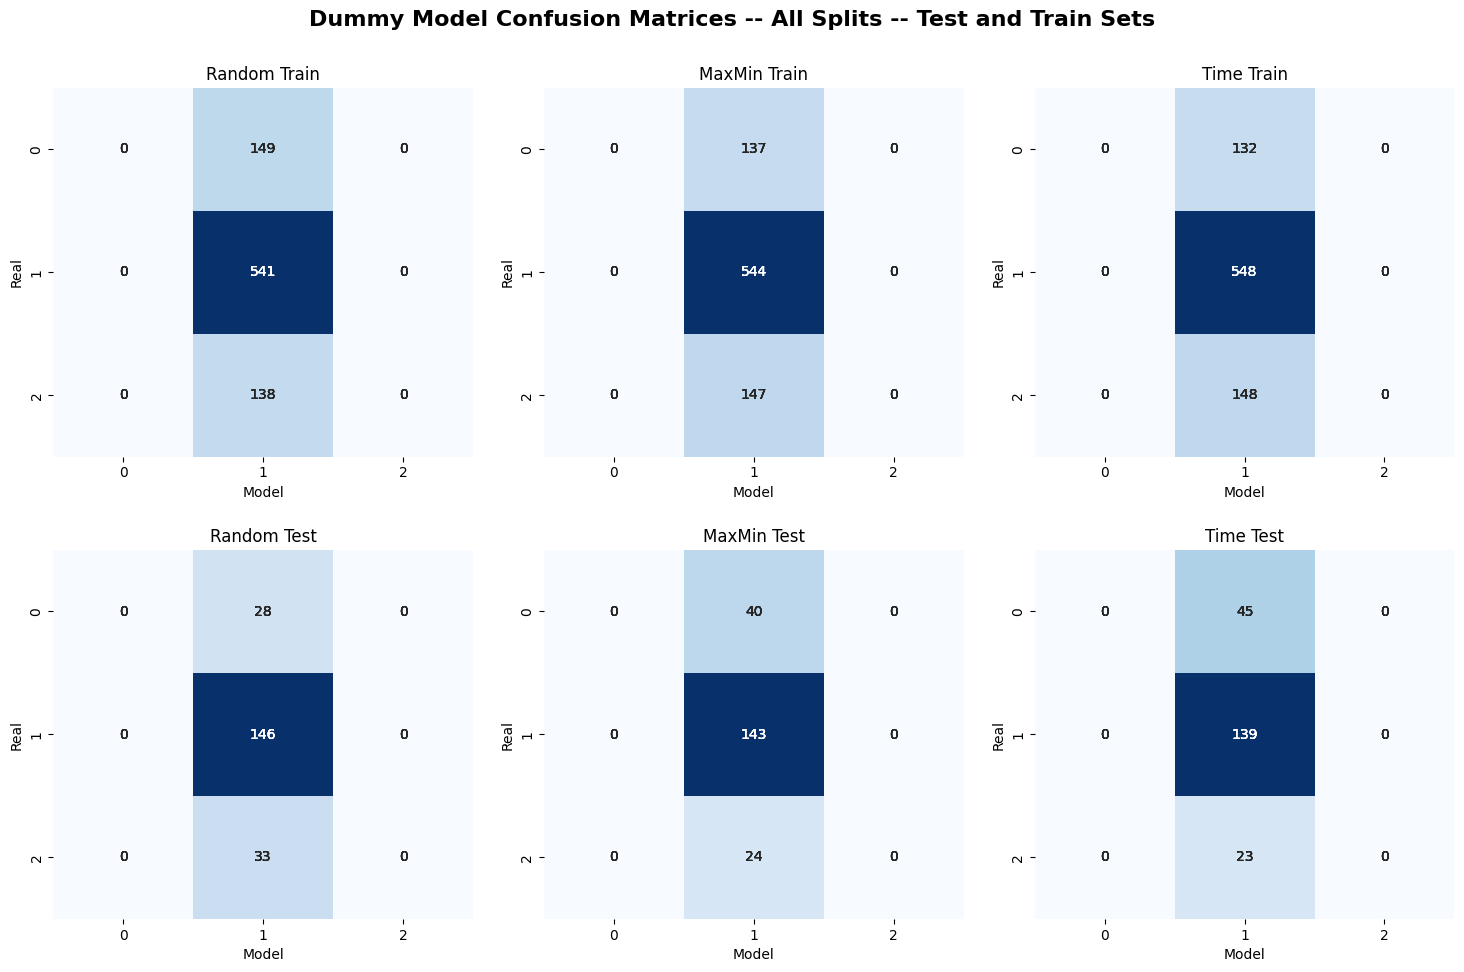

In [18]:
# function to plot confusion mtrx for a given model (all splits, test&train)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Dummy Model Confusion Matrices -- All Splits -- Test and Train Sets', fontsize=16, fontweight='bold')

descriptors_to_plot = ['Random Train', 'MaxMin Train', 'Time Train',
                        'Random Test', 'MaxMin Test', 'Time Test']

for i in enumerate(descriptors_to_plot):
    for i, descriptor in enumerate(descriptors_to_plot):
        row = i // 3
        col = i % 3

        if descriptor == "Random Train":
            cm = confusion_matrix(random_train[TARGET], random_dummy.predict(random_train[RANDOM_FEATURES]))
        elif descriptor == "MaxMin Train":
            cm = confusion_matrix(maxmin_train[TARGET], maxmin_dummy.predict(maxmin_train[MAXMIN_FEATURES]))
        elif descriptor == "Time Train":
            cm = confusion_matrix(time_train[TARGET], time_dummy.predict(time_train[TIME_FEATURES]))
        elif descriptor == "Random Test":
            cm = confusion_matrix(random_test[TARGET], random_dummy.predict(random_test[RANDOM_FEATURES]))
        elif descriptor == "MaxMin Test":
            cm = confusion_matrix(maxmin_test[TARGET], maxmin_dummy.predict(maxmin_test[MAXMIN_FEATURES]))
        elif descriptor == "Time Test":
            cm = confusion_matrix(time_test[TARGET], time_dummy.predict(time_test[TIME_FEATURES]))

        sns.heatmap(cm, annot=True, fmt='.0f', cmap='Blues', ax=axes[row, col], cbar=False)
        axes[row, col].set_title(descriptor)
        axes[row, col].set_ylabel("Real")
        axes[row, col].set_xlabel("Model")
    col = i % 3

plt.tight_layout(pad=2)
plt.show();

#### Training Random Forest Model
Hyperparameters are tuned using 5-fold cross-validation, model with highest marco F1 is selected.

In [19]:
assert len(fingerprint_df) == len(df) #checks that both tables have the same number of rows.
assert df["SMILES"].is_unique #checks that each SMILES appears only once in df.
# If either check fails, Python stops with an error.

Random Forest grid_search 

In [20]:
# Random Forest for the whole random training set
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

X_random_train = random_train[RANDOM_FEATURES]
y_random_train = random_train[TARGET]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rfc = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced",
    random_state=RANDOM_SEED
)

rfc_param_grid = {
    "criterion": ["gini", "entropy", "log_loss"],
    "max_features": [100, 0.1, "sqrt", "log2", None],
    "max_depth": [5, 10, 20, None]
} 

grid_rfc = GridSearchCV(
    rfc,
    rfc_param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
)

grid_rfc.fit(X_random_train, y_random_train)

print(grid_rfc.best_params_)
print(grid_rfc.best_score_)
# this code will take a few minutes

,estimator,RandomForestC...om_state=1147)
,param_grid,"{'criterion': ['gini', 'entropy', ...], 'max_depth': [5, 10, ...], 'max_features': [100, 0.1, ...]}"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,500


{'criterion': 'gini', 'max_depth': 20, 'max_features': 0.1}
0.5743930278956324


In [21]:
# compare the best hyper parameter for max_depth of 10 and 20
results = pd.DataFrame(grid_rfc.cv_results_)

best_by_depth = (
    results.loc[results["param_max_depth"].isin([10, 20])]
    .sort_values("mean_test_score", ascending=False)
    .drop_duplicates("param_max_depth")
    .sort_values("param_max_depth")
)

display(best_by_depth[[
    "param_max_depth", "param_criterion", "param_max_features",
    "mean_test_score", "std_test_score"
]].rename(columns={
    "mean_test_score": "Mean validation macro F1",
    "std_test_score": "SD across folds"
}).round(4))

,param_max_depth,param_criterion,param_max_features,Mean validation macro F1,SD across folds
47,10,log_loss,sqrt,0.5729,0.0149
11,20,gini,0.1,0.5744,0.0135


The maximum-depth-10 configuration achieved a mean validation macro F1 of 0.5729, compared with 0.5744 for the best depth-20 configuration. Since the improvement was only 0.0015, depth 10 was selected to favor simpler
trees and reduce potential overfitting while retaining nearly the same validation performance.

Base model for random forest model

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

# Define the base Random Forest configuration 
base_rf = RandomForestClassifier(
    n_estimators=500,
    criterion="entropy",
    max_features="sqrt",
    max_depth=10,
    class_weight="balanced",
    random_state=RANDOM_SEED,
    n_jobs=-1
)

# Clone the base model and rrain a separate model for each split
random_rf = clone(base_rf).fit(random_train[RANDOM_FEATURES], random_train[TARGET])
maxmin_rf = clone(base_rf).fit(maxmin_train[MAXMIN_FEATURES], maxmin_train[TARGET])
time_rf = clone(base_rf).fit(time_train[TIME_FEATURES], time_train[TARGET])

Error matrics for the Random Forest model

In [23]:
from sklearn.metrics import (
    accuracy_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
)
# Calculate training and test metrics for each split
rf_metrics = {
    "Random Train": get_regression_metrics(
        random_rf, random_train,
        random_train[RANDOM_FEATURES], random_train[TARGET]
    ),
    "Random Test": get_regression_metrics(
        random_rf, random_test,
        random_test[RANDOM_FEATURES], random_test[TARGET]
    ),
    "MaxMin Train": get_regression_metrics(
        maxmin_rf, maxmin_train,
        maxmin_train[MAXMIN_FEATURES], maxmin_train[TARGET]
    ),
    "MaxMin Test": get_regression_metrics(
        maxmin_rf, maxmin_test,
        maxmin_test[MAXMIN_FEATURES], maxmin_test[TARGET]
    ),
    "Time Train": get_regression_metrics(
        time_rf, time_train,
        time_train[TIME_FEATURES], time_train[TARGET]
    ),
    "Time Test": get_regression_metrics(
        time_rf, time_test,
        time_test[TIME_FEATURES], time_test[TARGET]
    )
}

# Display the results in a table
display(pd.DataFrame.from_dict(rf_metrics, orient="index").round(3))

,F1,weighted F1,MCC,accuracy,precision,weighted precision,recall,weighted recall
Random Train,0.875,0.898,0.809,0.897,0.862,0.903,0.895,0.897
Random Test,0.606,0.717,0.400,0.715,0.594,0.721,0.620,0.715
MaxMin Train,0.839,0.865,0.762,0.861,0.813,0.888,0.891,0.861
MaxMin Test,0.486,0.618,0.168,0.623,0.510,0.617,0.471,0.623
Time Train,0.876,0.898,0.803,0.897,0.861,0.901,0.894,0.897
Time Test,0.467,0.613,0.199,0.676,0.555,0.606,0.460,0.676


Confusion matrics for Random Forest model

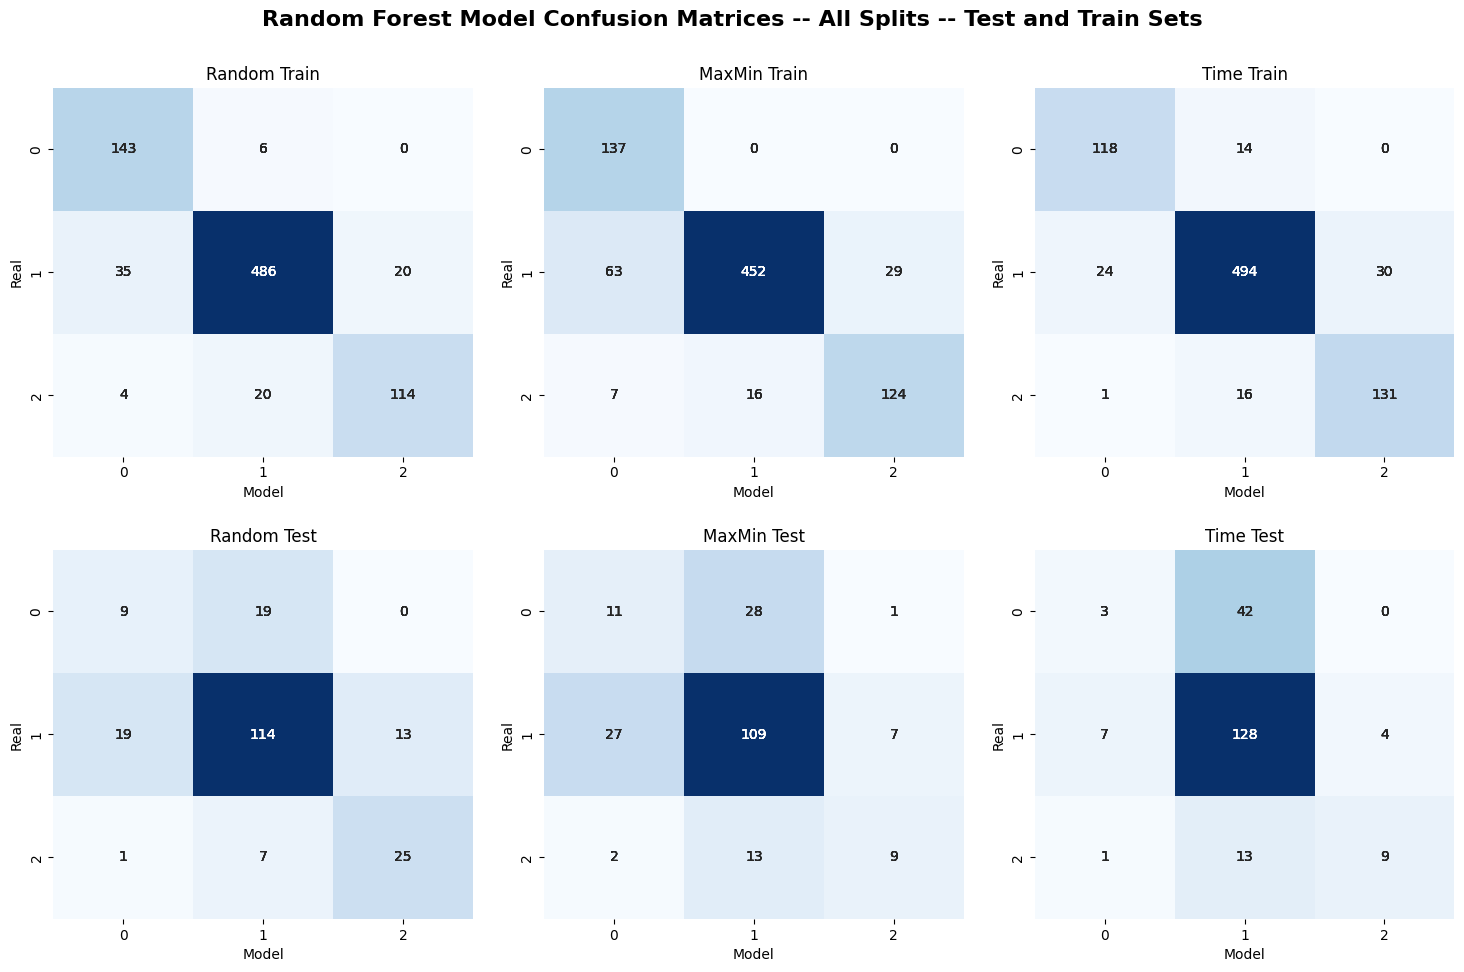

In [24]:
# Function to plot confusion mtrx for the random fores model (all splits, test&train)
from sklearn.metrics import confusion_matrix
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Random Forest Model Confusion Matrices -- All Splits -- Test and Train Sets', fontsize=16, fontweight='bold')

descriptors_to_plot = ['Random Train', 'MaxMin Train', 'Time Train',
                        'Random Test', 'MaxMin Test', 'Time Test']

for i in enumerate(descriptors_to_plot):
    for i, descriptor in enumerate(descriptors_to_plot):
        row = i // 3
        col = i % 3

        if descriptor == "Random Train":
            cm = confusion_matrix(random_train[TARGET], random_rf.predict(random_train[RANDOM_FEATURES]))
        elif descriptor == "MaxMin Train":
            cm = confusion_matrix(maxmin_train[TARGET], maxmin_rf.predict(maxmin_train[MAXMIN_FEATURES]))
        elif descriptor == "Time Train":
            cm = confusion_matrix(time_train[TARGET], time_rf.predict(time_train[TIME_FEATURES]))
        elif descriptor == "Random Test":
            cm = confusion_matrix(random_test[TARGET], random_rf.predict(random_test[RANDOM_FEATURES]))
        elif descriptor == "MaxMin Test":
            cm = confusion_matrix(maxmin_test[TARGET], maxmin_rf.predict(maxmin_test[MAXMIN_FEATURES]))
        elif descriptor == "Time Test":
            cm = confusion_matrix(time_test[TARGET], time_rf.predict(time_test[TIME_FEATURES]))

        sns.heatmap(cm, annot=True, fmt='.0f', cmap='Blues', ax=axes[row, col], cbar=False)
        axes[row, col].set_title(descriptor)
        axes[row, col].set_ylabel("Real")
        axes[row, col].set_xlabel("Model")
    col = i % 3

plt.tight_layout(pad=2)
plt.show();

### Training XGBoost Model
https://xgboost.readthedocs.io/en/stable/ 


In [25]:
# Define the common XGBoost configuration
bst = XGBClassifier(num_class= 3, n_estimators=13, max_depth=4, learning_rate=0.5, random_state = RANDOM_SEED)

# Train a separate model for each split
random_bst = clone(bst).fit(random_train[RANDOM_FEATURES],random_train[TARGET])
maxmin_bst = clone(bst).fit(maxmin_train[MAXMIN_FEATURES], maxmin_train[TARGET])
time_bst = clone(bst).fit(time_train[TIME_FEATURES], time_train[TARGET])

#create a list of dummy models 
bst_models = [
    ('random', random_bst),
    ('maxmin', maxmin_bst),
    ('time', time_bst),
]

# initialize dictionaries for error metrics
bst_results_test = {} # initialize empty dictionary
bst_results_train = {}

# Calculate training and test metrics for each split
bst_results_test['random'] = get_regression_metrics(random_bst, random_test, random_test[RANDOM_FEATURES], random_test[TARGET])
bst_results_train['random'] = get_regression_metrics(random_bst, random_train, random_train[RANDOM_FEATURES], random_train[TARGET])
bst_results_test['maxmin'] = get_regression_metrics(maxmin_bst, maxmin_test, maxmin_test[MAXMIN_FEATURES], maxmin_test[TARGET])
bst_results_train['maxmin'] = get_regression_metrics(maxmin_bst, maxmin_train, maxmin_train[MAXMIN_FEATURES], maxmin_train[TARGET])
bst_results_test['time'] = get_regression_metrics(time_bst, time_test, time_test[TIME_FEATURES], time_test[TARGET])
bst_results_train['time'] = get_regression_metrics(time_bst, time_train, time_train[TIME_FEATURES], time_train[TARGET])



Error matrics for the XGBoost model

In [26]:
# Combine training and test metrics
bst_metrics = {
    "Random Train": bst_results_train["random"],
    "Random Test": bst_results_test["random"],
    "MaxMin Train": bst_results_train["maxmin"],
    "MaxMin Test": bst_results_test["maxmin"],
    "Time Train": bst_results_train["time"],
    "Time Test": bst_results_test["time"]
}

# Display the results in a table
display(pd.DataFrame.from_dict(bst_metrics, orient="index").round(3))

,F1,weighted F1,MCC,accuracy,precision,weighted precision,recall,weighted recall
Random Train,0.707,0.784,0.625,0.815,0.892,0.843,0.670,0.815
Random Test,0.641,0.778,0.547,0.812,0.867,0.832,0.611,0.812
MaxMin Train,0.705,0.790,0.623,0.818,0.874,0.836,0.666,0.818
MaxMin Test,0.453,0.635,0.257,0.715,0.637,0.673,0.455,0.715
Time Train,0.730,0.811,0.656,0.835,0.884,0.850,0.691,0.835
Time Test,0.489,0.636,0.341,0.720,0.828,0.782,0.488,0.720


Confusion matrics for XGBoost model

In [27]:
# Plot XGBoost confusion matrices for all splits 
def confusion_plots(random_model, maxmin_model, time_model, name_string):
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    fig.suptitle(f"{name_string} Model Confusion Matrices -- All Splits -- Test and Train Sets", fontsize=16, fontweight='bold')

    descriptors_to_plot = ['Random Train', 'MaxMin Train', 'Time Train',
                        'Random Test', 'MaxMin Test', 'Time Test']

    for i in enumerate(descriptors_to_plot):
        for i, descriptor in enumerate(descriptors_to_plot):
            row = i // 3
            col = i % 3

            if descriptor == "Random Train":
                cm = confusion_matrix(random_train[TARGET], random_model.predict(random_train[RANDOM_FEATURES]))
            elif descriptor == "MaxMin Train":
                cm = confusion_matrix(maxmin_train[TARGET], maxmin_model.predict(maxmin_train[MAXMIN_FEATURES]))
            elif descriptor == "Time Train":
                cm = confusion_matrix(time_train[TARGET], time_model.predict(time_train[TIME_FEATURES]))
            elif descriptor == "Random Test":
                cm = confusion_matrix(random_test[TARGET], random_model.predict(random_test[RANDOM_FEATURES]))
            elif descriptor == "MaxMin Test":
                cm = confusion_matrix(maxmin_test[TARGET], maxmin_model.predict(maxmin_test[MAXMIN_FEATURES]))
            elif descriptor == "Time Test":
                cm = confusion_matrix(time_test[TARGET], time_model.predict(time_test[TIME_FEATURES]))

            sns.heatmap(cm, annot=True, fmt='.0f', cmap='Blues', ax=axes[row, col], cbar=False)
            axes[row, col].set_title(descriptor)
            axes[row, col].set_ylabel("Real")
            axes[row, col].set_xlabel("Model")
        col = i % 3

    plt.tight_layout(pad=2)
    plt.show();

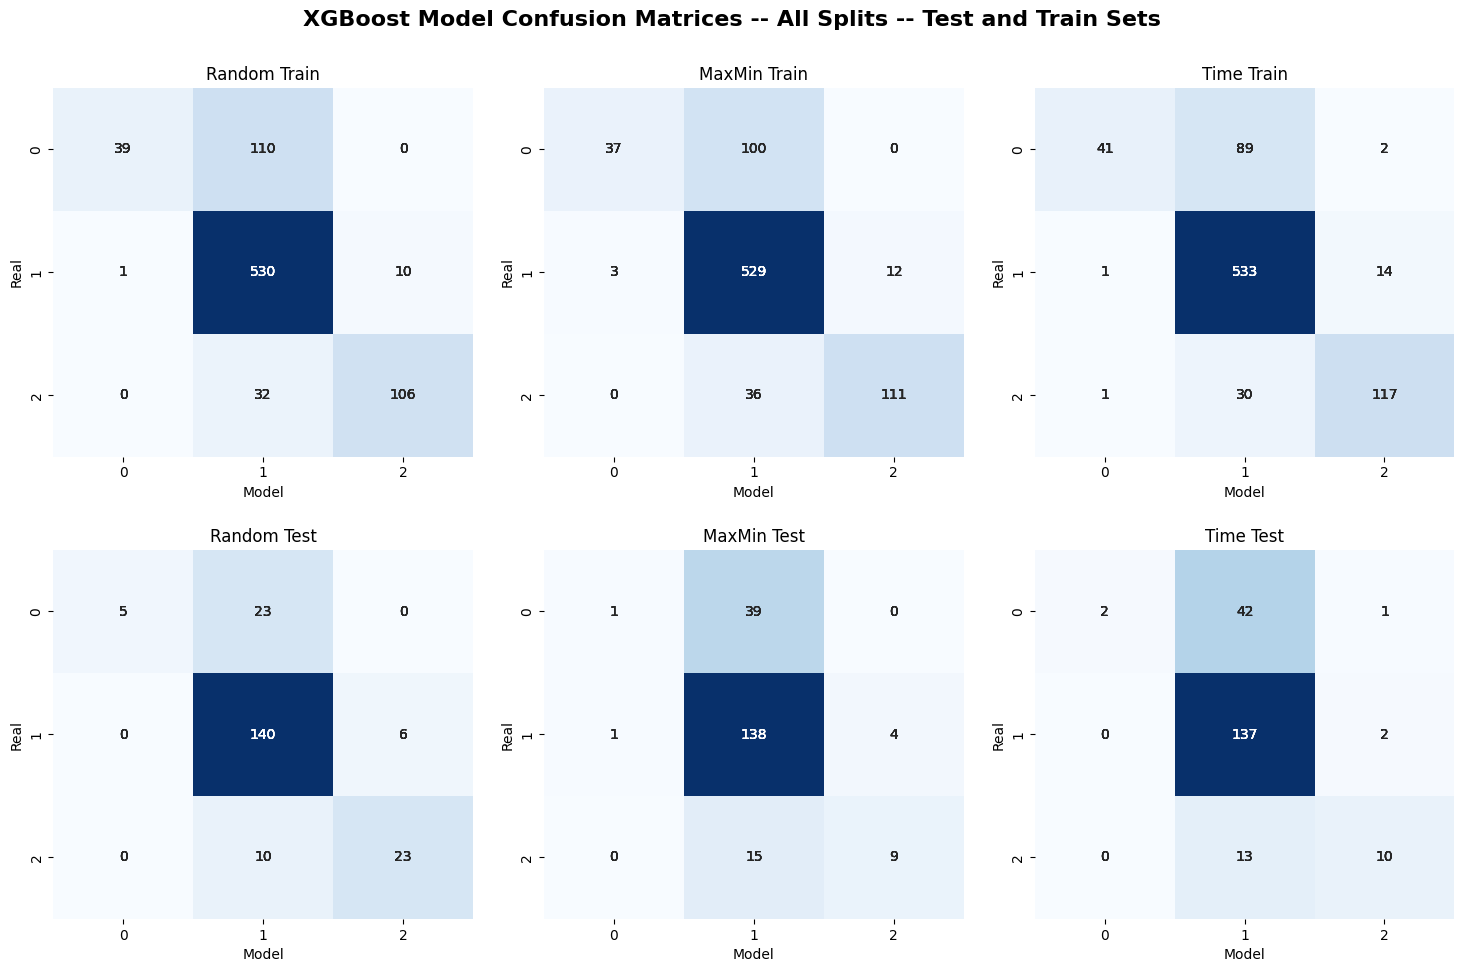

In [28]:
# Display the confusion matrix
confusion_plots(random_bst, maxmin_bst, time_bst, 'XGBoost')

### Training Support Vector Classification (SVC) model

Hyperparameter Tuning

C is the Controls decision boundary flexibility
    Small value (0.1) gives a smoother boundary
    Large Value (100) gives a More complex boundary and more risk of overfitting

Gamma - Controls how far a molecule's influence extends
    small (0.001) gives smooth global boundaries
    large (1) gives very local boundaries and can overfit badly

In [29]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
# cross validation split
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_SEED
)

Grid_search for the SVC model

In [30]:
from sklearn.svm import SVC

svm = SVC(
    kernel="rbf",
    class_weight="balanced",
    probability=True,
    random_state=RANDOM_SEED
)

svm_param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.001, 0.01, 0.1, "scale"]
}

grid_svm = GridSearchCV(
    svm,
    svm_param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

grid_svm.fit(fingerprint_df, df['ppdb_level'])

print(grid_svm.best_params_)
print(grid_svm.best_score_)
# this code will take a few minutes

,estimator,SVC(class_wei...om_state=1147)
,param_grid,"{'C': [0.1, 1, ...], 'gamma': [0.001, 0.01, ...]}"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,1


{'C': 1, 'gamma': 'scale'}
0.5877982451948782


In [31]:
# Create Dictionary Containing Error Metrics 
def get_regression_metrics(model, dataframe, X, y_true):
    """
    Get a dictionary w/ metrics: 'model' is sklearn model w/ predict method,
    'X' is dataframe(FEATURES), 'y' is dataframe(TARGET)
    """
    y_pred = model.predict(X)

    f1 = f1_score(y_true, y_pred, average= 'macro', zero_division=0)
    mcc = matthews_corrcoef(y_true, y_pred)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro', zero_division=0) # Add zero_division=0 to handle cases with no positive predictions
    rec = recall_score(y_true, y_pred, average='macro', zero_division=0)
    #confusion = confusion_matrix(y_true, model.predict(X), normalize='true')
    #report = classification_report(y_true, y_pred, zero_division=0)
    # ^ bring these back later

    metrics_dict = {
        'F1': f1,
        'MCC': mcc,
        'accuracy': acc,
        'precision':  prec, 
        'recall': rec,
      #  'confusion matrix': confusion,
      #  'classification_report': report
      # bring these back ater ^
    }

    return metrics_dict

SVC Model Testing

In [32]:
from sklearn.svm import SVC

svm = SVC(
    kernel="rbf",
    class_weight="balanced",
    probability=True,
    random_state=RANDOM_SEED,
    C=1,
    gamma='scale'
)


In [33]:
from sklearn.base import clone
# Fit independent models for each split

random_svc = clone(svm).fit(random_train[RANDOM_FEATURES], random_train[TARGET])
maxmin_svc = clone(svm).fit(maxmin_train[MAXMIN_FEATURES], maxmin_train[TARGET])
time_svc = clone(svm).fit(time_train[TIME_FEATURES], maxmin_train[TARGET])

#if creating loop
#create a list of dummy models 
svc_models = [
    ('random', random_svc),
    ('maxmin', maxmin_svc),
    ('time', time_svc),
]

# initialize dictionaries for error metrics
svc_results_test = {}
svc_results_train = {}

svc_results_test['random'] = get_regression_metrics(random_svc, random_test, random_test[RANDOM_FEATURES], random_test[TARGET])
svc_results_train['random'] = get_regression_metrics(random_svc, random_train, random_train[RANDOM_FEATURES], random_train[TARGET])
svc_results_test['maxmin'] = get_regression_metrics(maxmin_svc, maxmin_test, maxmin_test[MAXMIN_FEATURES], maxmin_test[TARGET])
svc_results_train['maxmin'] = get_regression_metrics(maxmin_svc, maxmin_train, maxmin_train[MAXMIN_FEATURES], maxmin_train[TARGET])
svc_results_test['time'] = get_regression_metrics(time_svc, time_test, time_test[TIME_FEATURES], time_test[TARGET])
svc_results_train['time'] = get_regression_metrics(time_svc, time_train, time_train[TIME_FEATURES], time_train[TARGET])


Error matrics for SVC model

In [34]:
# Combine training and test metrics
svc_metrics = {
    "Random Train": svc_results_train["random"],
    "Random Test": svc_results_test["random"],
    "MaxMin Train": svc_results_train["maxmin"],
    "MaxMin Test": svc_results_test["maxmin"],
    "Time Train": svc_results_train["time"],
    "Time Test": svc_results_test["time"]
}

# Display the results in a table
display(pd.DataFrame.from_dict(svc_metrics, orient="index").round(3))

,F1,MCC,accuracy,precision,recall
Random Train,0.869,0.804,0.883,0.835,0.925
Random Test,0.616,0.411,0.686,0.594,0.660
MaxMin Train,0.846,0.777,0.864,0.810,0.914
MaxMin Test,0.511,0.201,0.667,0.566,0.485
Time Train,0.314,-0.016,0.414,0.323,0.320
Time Test,0.286,-0.039,0.406,0.313,0.292


Confusion matrics for the SVC model

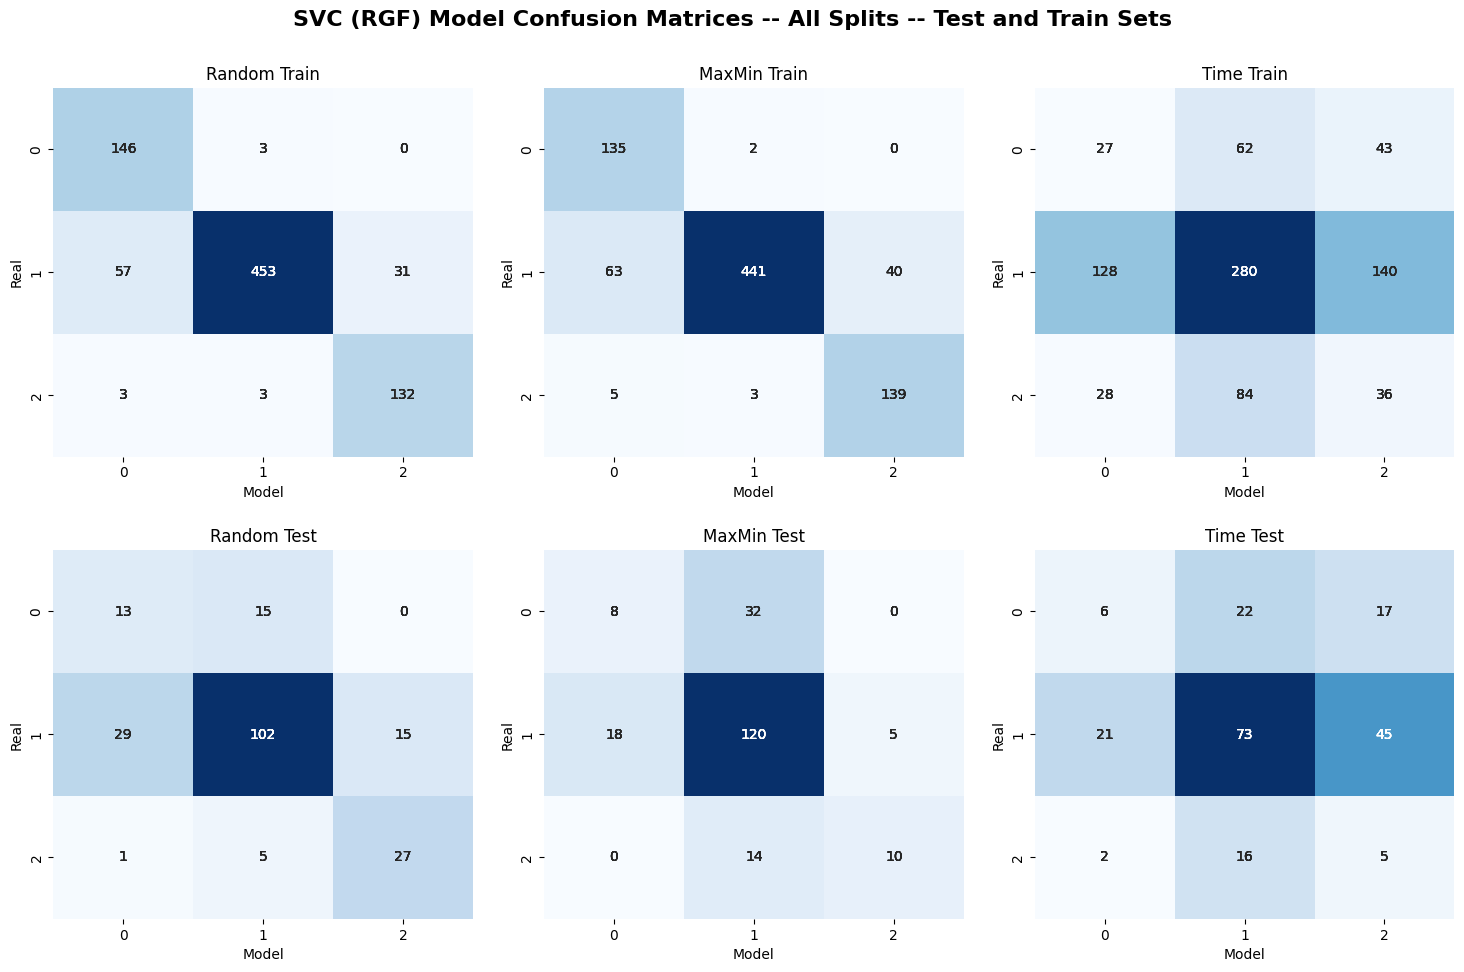

In [35]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('SVC (RGF) Model Confusion Matrices -- All Splits -- Test and Train Sets', fontsize=16, fontweight='bold')

descriptors_to_plot = ['Random Train', 'MaxMin Train', 'Time Train',
                        'Random Test', 'MaxMin Test', 'Time Test']

for i in enumerate(descriptors_to_plot):
    for i, descriptor in enumerate(descriptors_to_plot):
        row = i // 3
        col = i % 3

        if descriptor == "Random Train":
            cm = confusion_matrix(random_train[TARGET], random_svc.predict(random_train[RANDOM_FEATURES]))
        elif descriptor == "MaxMin Train":
            cm = confusion_matrix(maxmin_train[TARGET], maxmin_svc.predict(maxmin_train[MAXMIN_FEATURES]))
        elif descriptor == "Time Train":
            cm = confusion_matrix(time_train[TARGET], time_svc.predict(time_train[TIME_FEATURES]))
        elif descriptor == "Random Test":
            cm = confusion_matrix(random_test[TARGET], random_svc.predict(random_test[RANDOM_FEATURES]))
        elif descriptor == "MaxMin Test":
            cm = confusion_matrix(maxmin_test[TARGET], maxmin_svc.predict(maxmin_test[MAXMIN_FEATURES]))
        elif descriptor == "Time Test":
            cm = confusion_matrix(time_test[TARGET], time_svc.predict(time_test[TIME_FEATURES]))

        sns.heatmap(cm, annot=True, fmt='.0f', cmap='Blues', ax=axes[row, col], cbar=False)
        axes[row, col].set_title(descriptor)
        axes[row, col].set_ylabel("Real")
        axes[row, col].set_xlabel("Model")
    col = i % 3

plt.tight_layout(pad=2)
plt.show();